# Thí nghiệm 02 — Climate Figures

Notebook này tập hợp toàn bộ mã nguồn trực quan hóa kết quả thực nghiệm DeepKoopFormer trên các bộ dữ liệu Climate.

## Nội dung

- **Figure 3:** CMIP6 Wind — Grid Search MSE/MAE Heatmaps.
- **Figure 4:** CMIP6 Wind — Forecasting tại 5 vị trí.
- **Figure 5:** Surface Pressure — Grid Search MSE/MAE Heatmaps.
- **Figure 6:** Surface Pressure — Forecasting tại 5 vị trí.
- **Figure 7:** ERA5 Wind — Forecasting tại 10 địa điểm.
- **ERA5 Analysis:** Training Loss, Koopman Stability và MSE/MAE Comparison.
- **Figure 8:** Scenario 4 — Train Heatmaps.
- **Figure 9:** Scenario 4 — Test Heatmaps.
- **Figure 10:** Scenario 4 — Test Forecasting.

## Nguyên tắc

Toàn bộ hình được xây dựng từ các checkpoint và metric đã lưu.

Notebook không huấn luyện mô hình, không tạo lại dataset và không cập nhật trọng số.

Các hình đã tồn tại được bảo vệ khỏi việc ghi đè. Mặc định chỉ hiển thị hình trong notebook.


In [13]:
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt


# 1. Tìm thư mục gốc repository
project_root = next(
    (
        p for p in [Path.cwd(), *Path.cwd().parents]
        if (p / "experiments" / "02_climate").is_dir()
    ),
    None
)

if project_root is None:
    raise FileNotFoundError(
        "Không tìm thấy thư mục experiments/02_climate."
    )


# 2. Các thư mục của thí nghiệm Climate
experiment_dir = project_root / "experiments" / "02_climate"

results_root = experiment_dir / "results"
figures_dir = experiment_dir / "figures"

figures_dir.mkdir(parents=True, exist_ok=True)


# 3. Danh sách mô hình
MODELS = ["LSTM", "PatchTST", "Autoformer", "Informer"]


# 4. Cho phép xuất hình PNG
SAVE_FIGURES = True


# 5. Hàm đọc checkpoint (chỉ đọc, không thay đổi trọng số)
def load_checkpoint(path):
    path = Path(path)

    if not path.is_file():
        raise FileNotFoundError(path)

    return torch.load(
        path,
        map_location="cpu",
        weights_only=True
    )


# 6. Hàm lưu toàn bộ hình vào figures/
def safe_save_figure(fig, filename):
    output_path = figures_dir / Path(filename).name

    if not SAVE_FIGURES:
        print("Preview only:", output_path.name)
        return

    # Không ghi đè PNG đã tồn tại
    if output_path.exists():
        print("Already exists, skipped:", output_path)
        return

    fig.savefig(
        output_path,
        dpi=300,
        bbox_inches="tight"
    )

    print("Saved:", output_path)

# 7. Nạp kết quả Scenario 4 một lần duy nhất
scenario4_dir = (
    results_root / "scenario4_train_test_e4000"
)

scenario4_metrics_path = scenario4_dir / "metrics.csv"

if not scenario4_metrics_path.is_file():
    raise FileNotFoundError(scenario4_metrics_path)

scenario4_df = pd.read_csv(scenario4_metrics_path)

# Kiểm tra dữ liệu
assert len(scenario4_df) == 448
assert (scenario4_df["Set"] == "Train").sum() == 224
assert (scenario4_df["Set"] == "Test").sum() == 224

print("Scenario 4 metrics:", scenario4_df.shape)


print("=== CLIMATE FIGURES ===")
print("Project:", project_root)
print("Results:", results_root)
print("Figures:", figures_dir)
print("Saving enabled:", SAVE_FIGURES)

Scenario 4 metrics: (448, 8)
=== CLIMATE FIGURES ===
Project: c:\Users\Win 11 New\Desktop\pa gk
Results: c:\Users\Win 11 New\Desktop\pa gk\experiments\02_climate\results
Figures: c:\Users\Win 11 New\Desktop\pa gk\experiments\02_climate\figures
Saving enabled: True


## Figure 3 — CMIP6 Wind Speed: Grid Search Heatmaps

Hình biểu diễn MSE và MAE của bốn mô hình dự báo tốc độ gió CMIP6 theo hai siêu tham số:

- Patch length: 80, 90, 100, 110, 120, 130.
- Forecast horizon: 10, 15, 20, 25, 30.

Cấu hình chung: `d_model = 48`, `epochs = 4000`.

Tổng cộng 120 lượt huấn luyện.

Hình gồm bốn hàng tương ứng bốn mô hình và hai cột tương ứng MSE và MAE.

Dữ liệu được lấy từ `results/climate_grid_search_e4000/metrics.csv`.

=== GRID SEARCH: 4000 EPOCHS ===
Total runs: 120
Metrics: c:\Users\Win 11 New\Desktop\pa gk\experiments\02_climate\results\climate_grid_search_e4000\metrics.csv
Saved: c:\Users\Win 11 New\Desktop\pa gk\experiments\02_climate\figures\figure3_wind_heatmaps.png


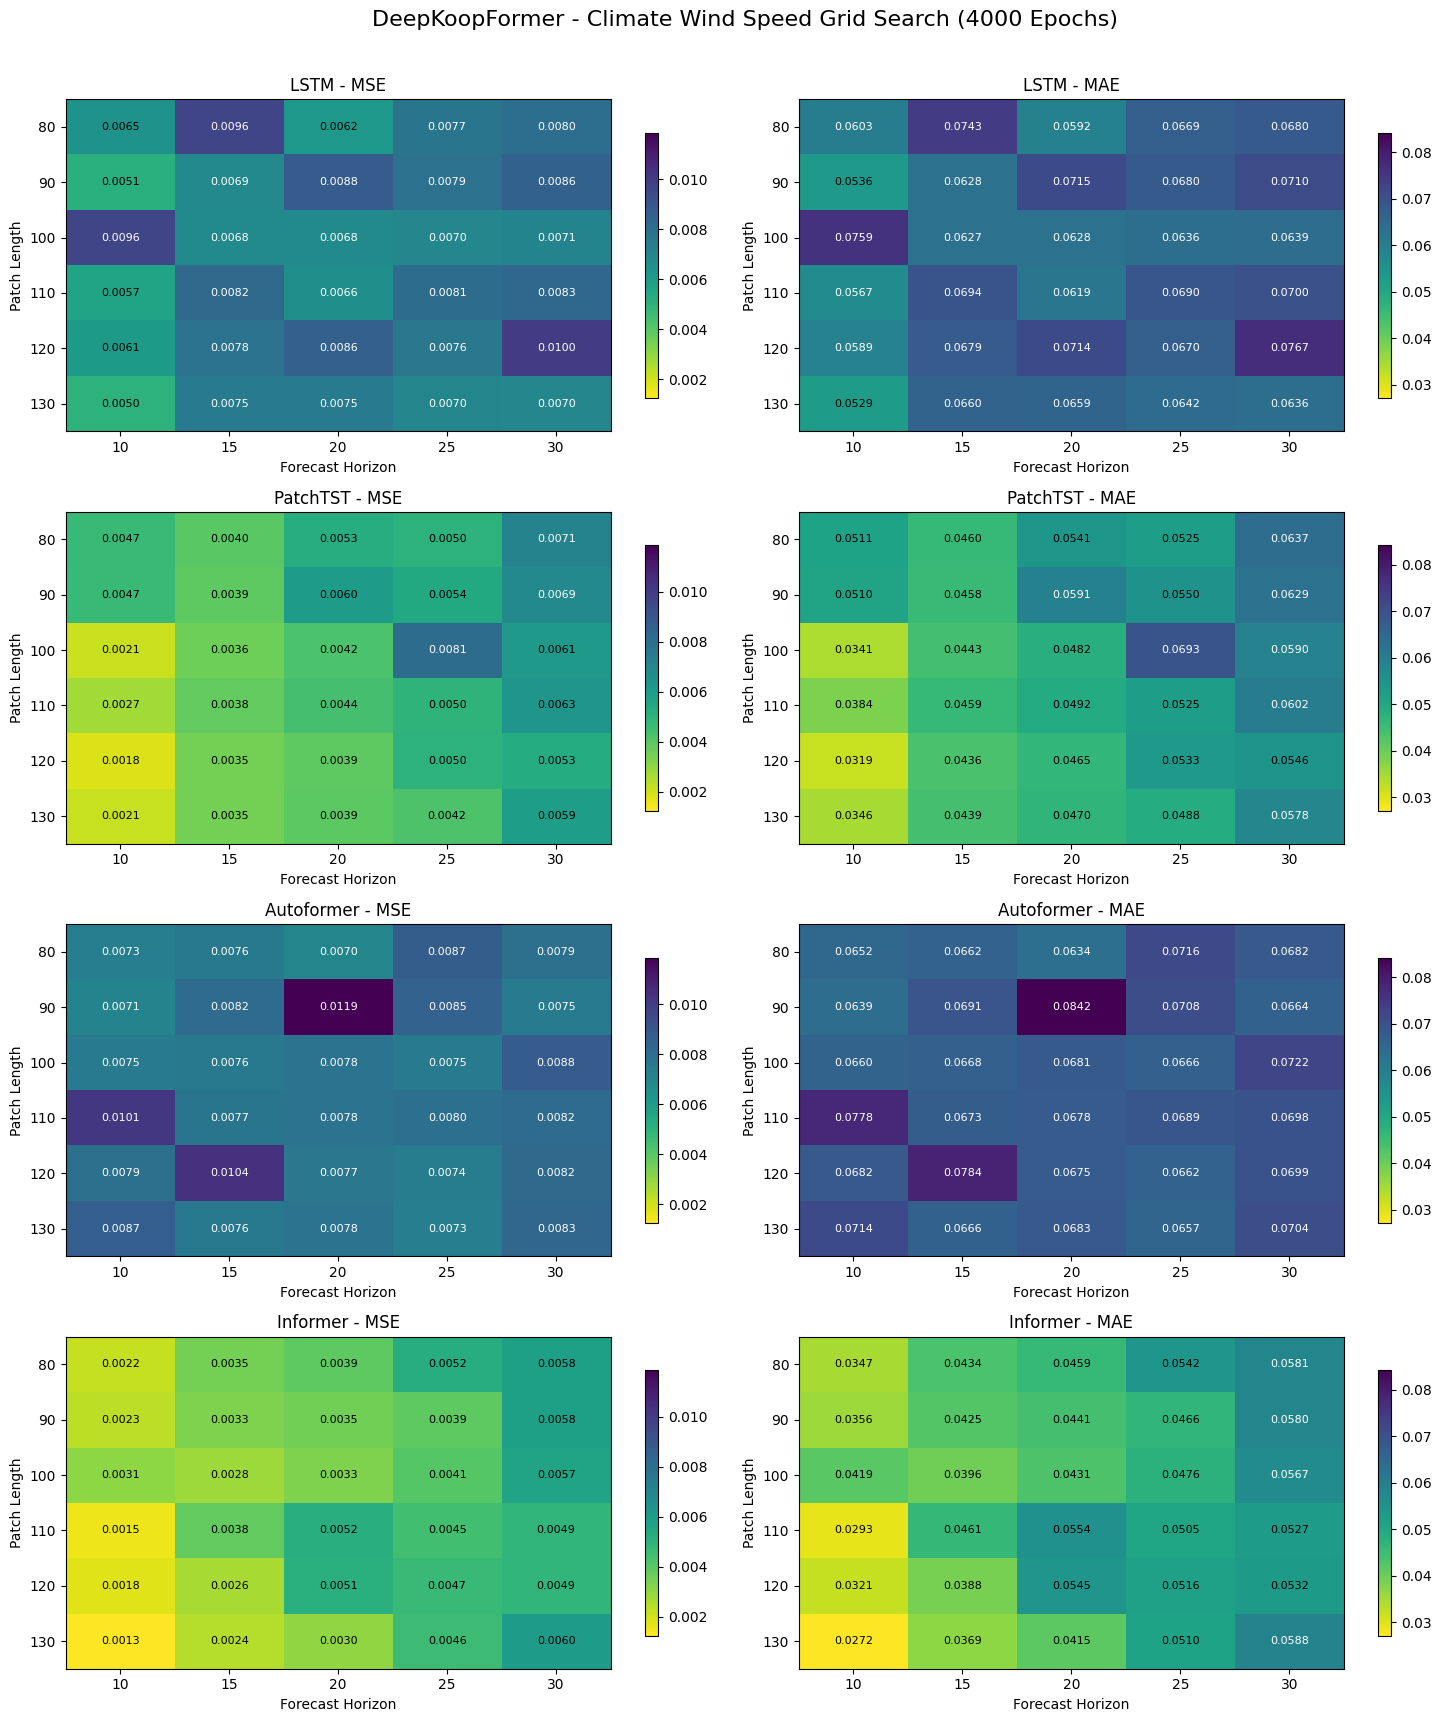

In [4]:
# Figure 3 — CMIP6 Wind Speed Grid Search

results_dir = results_root / "climate_grid_search_e4000"
metrics_path = results_dir / "metrics.csv"

# Cấu hình của CMIP6 Wind
patch_lengths = [80, 90, 100, 110, 120, 130]
horizons = [10, 15, 20, 25, 30]

if not metrics_path.exists():
    raise FileNotFoundError(f"Metrics not found: {metrics_path}")

metrics = pd.read_csv(metrics_path)

model_names = ["LSTM", "PatchTST", "Autoformer", "Informer"]
metric_names = ["MSE", "MAE"]

# 2. Verify all configurations
expected = {
    (m, p, h)
    for m in model_names
    for p in patch_lengths
    for h in horizons
}

actual = set(
    zip(metrics["Model"], metrics["PatchLen"], metrics["Horizon"])
)

assert expected == actual, f"Missing configurations: {expected - actual}"
assert len(metrics) == 120, f"Expected 120 runs, got {len(metrics)}"

print("=== GRID SEARCH: 4000 EPOCHS ===")
print("Total runs:", len(metrics))
print("Metrics:", metrics_path)

# 3. Shared color scales for fair model comparison
scales = {
    metric: (metrics[metric].min(), metrics[metric].max())
    for metric in metric_names
}

fig, axes = plt.subplots(4, 2, figsize=(15, 17))

for row, model_name in enumerate(model_names):
    model_data = metrics[metrics["Model"] == model_name]

    for col, metric_name in enumerate(metric_names):
        ax = axes[row, col]

        heatmap_data = model_data.pivot(
            index="PatchLen",
            columns="Horizon",
            values=metric_name
        ).reindex(index=patch_lengths, columns=horizons)

        values = heatmap_data.to_numpy()
        vmin, vmax = scales[metric_name]

        im = ax.imshow(
            values,
            cmap="viridis_r",
            aspect="auto",
            vmin=vmin,
            vmax=vmax
        )

        for i in range(len(patch_lengths)):
            for j in range(len(horizons)):
                value = values[i, j]

                ax.text(
                    j, i, f"{value:.4f}",
                    ha="center",
                    va="center",
                    fontsize=8,
                    color="white" if im.norm(value) > 0.5 else "black"
                )

        ax.set_xticks(range(len(horizons)), horizons)
        ax.set_yticks(range(len(patch_lengths)), patch_lengths)

        ax.set_xlabel("Forecast Horizon")
        ax.set_ylabel("Patch Length")
        ax.set_title(f"{model_name} - {metric_name}")
        fig.colorbar(im, ax=ax, shrink=0.8)

fig.suptitle(
    "DeepKoopFormer - Climate Wind Speed Grid Search (4000 Epochs)",
    fontsize=16, y=1.01
)

plt.tight_layout()

# Xuất Figure 3 vào figures/
safe_save_figure(
    fig,
    "figure3_wind_heatmaps.png"
)

plt.show()


## Figure 4 — CMIP6 Wind Speed Forecasting

So sánh dự báo của LSTM, PatchTST, Autoformer và Informer với Ground Truth tại năm vị trí không gian.

Cấu hình:

- Patch length: 130.
- Forecast horizon: 20.
- `d_model = 48`.
- Epochs: 4000.
- Số kênh: 5.

Dự báo được đọc từ bốn checkpoint có cùng cấu hình trong `climate_grid_search_e4000`.

Mỗi đường biểu diễn bước dự báo đầu tiên của những cửa sổ trượt liên tiếp.

Giá trị hiển thị nằm trong không gian chuẩn hóa đã sử dụng khi huấn luyện.

c:\Users\Win 11 New\Desktop\pa gk\.venv\lib\site-packages\torch\_utils.py:776: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()


LSTM: MSE=0.007477, MAE=0.065927
PatchTST: MSE=0.003921, MAE=0.046967
Autoformer: MSE=0.007805, MAE=0.068256
Informer: MSE=0.003011, MAE=0.041517
Saved: c:\Users\Win 11 New\Desktop\pa gk\experiments\02_climate\figures\figure4_wind_forecasting.png


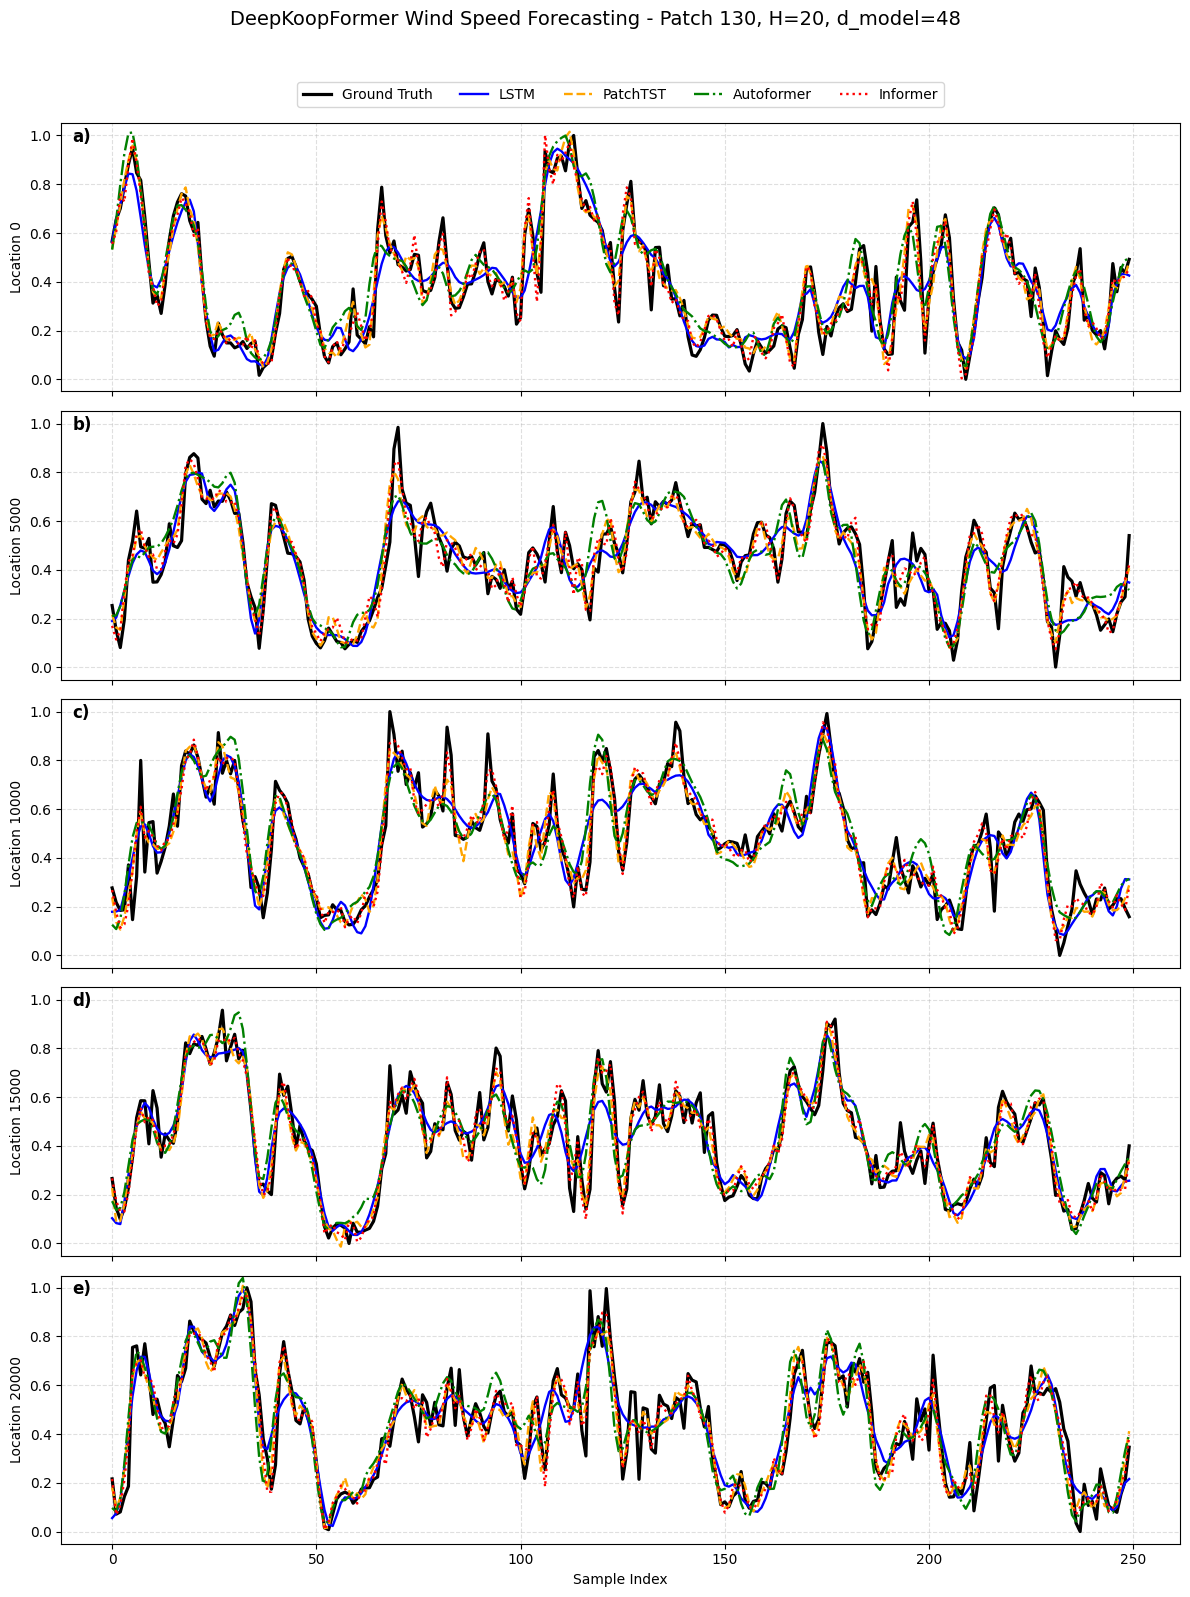

In [5]:
# Figure 4 — Nạp dữ liệu CMIP6 Wind
results_dir = results_root / "climate_grid_search_e4000"

wind_dataset = load_checkpoint(
    experiment_dir / "data" / "wind_nearest_5sites.pt"
)

location_indices = wind_dataset["location_indices"]
input_dim = len(location_indices)

assert input_dim == 5

fig4_patch = 130
fig4_horizon = 20

model_files = {
    "LSTM": "lstm",
    "PatchTST": "patchtst",
    "Autoformer": "autoformer",
    "Informer": "informer"
}

# 1. Load saved predictions
fig4_results = {}

for name, filename in model_files.items():
    path = results_dir / f"{filename}_p{fig4_patch}_h{fig4_horizon}.pt"
    checkpoint = load_checkpoint(path)
    fig4_results[name] = checkpoint

    print(f"{name}: MSE={checkpoint['mse']:.6f}, MAE={checkpoint['mae']:.6f}")

# Kiểm tra bốn checkpoint sử dụng cùng nhãn
reference_truth = fig4_results["LSTM"]["truth"]

for name, checkpoint in fig4_results.items():
    assert torch.allclose(
        checkpoint["truth"],
        reference_truth,
        atol=1e-6,
        rtol=1e-6
    ), f"Ground Truth không khớp: {name}"

# 2. Reshape outputs: (250, 100) -> (250, 5, 20)
N = fig4_results["LSTM"]["truth"].shape[0]
F = input_dim
H = fig4_horizon

ground_truth = fig4_results["LSTM"]["truth"].numpy().reshape(N, F, H)[:, :, 0]

predictions = {
    name: ckpt["pred"].numpy().reshape(N, F, H)[:, :, 0]
    for name, ckpt in fig4_results.items()
}

# 3. Match Figure 4 line styles
styles = {
    "LSTM":       {"color": "blue",   "linestyle": "-"},
    "PatchTST":   {"color": "orange", "linestyle": "--"},
    "Autoformer": {"color": "green",  "linestyle": "-."},
    "Informer":   {"color": "red",    "linestyle": ":"}
}

fig, axes = plt.subplots(F, 1, figsize=(12, 16), sharex=True)

for site, ax in enumerate(axes):
    ax.plot(
        np.arange(N), ground_truth[:, site],
        color="black", linewidth=2.3,
        label="Ground Truth"
    )

    for name, pred in predictions.items():
        ax.plot(
            np.arange(N), pred[:, site],
            linewidth=1.7,
            label=name,
            **styles[name]
        )

    ax.set_ylabel(f"Location {location_indices[site]}")
    ax.set_ylim(-0.05, 1.05)
    ax.grid(True, linestyle="--", alpha=0.4)

    ax.text(
        0.01, 0.93, f"{chr(97 + site)})",
        transform=ax.transAxes,
        fontsize=12, fontweight="bold"
    )

axes[0].legend(ncol=5, loc="upper center", bbox_to_anchor=(0.5, 1.18))
axes[-1].set_xlabel("Sample Index")

fig.suptitle(
    "DeepKoopFormer Wind Speed Forecasting - Patch 130, H=20, d_model=48",
    fontsize=14,
    y=0.995
)

plt.tight_layout(rect=[0, 0, 1, 0.975])

safe_save_figure(
    fig,
    "figure4_wind_forecasting.png"
)

plt.show()


## Figure 5 — Surface Pressure: Grid Search Heatmaps

Hình biểu diễn MSE và MAE của bốn mô hình trên dữ liệu Surface Pressure tại năm vị trí không gian.

Không gian thực nghiệm:

- Patch length cố định: 120.
- Forecast horizons: 10, 15, 20, 25, 30.
- `d_model`: 8, 16, 24, 32, 40, 48.
- Epochs: 4000.

Tổng cộng 120 lượt huấn luyện.

Mỗi hàng thể hiện một mô hình và mỗi cột thể hiện một metric.

Dữ liệu được đọc từ `pressure_5channels_grid_e4000/metrics.csv`.

Phần cuối hiển thị cấu hình có MSE thấp nhất của từng mô hình.

=== SURFACE PRESSURE: 4000 EPOCHS ===
Metrics: c:\Users\Win 11 New\Desktop\pa gk\experiments\02_climate\results\pressure_5channels_grid_e4000\metrics.csv
Total runs: 120
Checkpoints: 120
Saved: c:\Users\Win 11 New\Desktop\pa gk\experiments\02_climate\figures\figure5_pressure_heatmaps.png


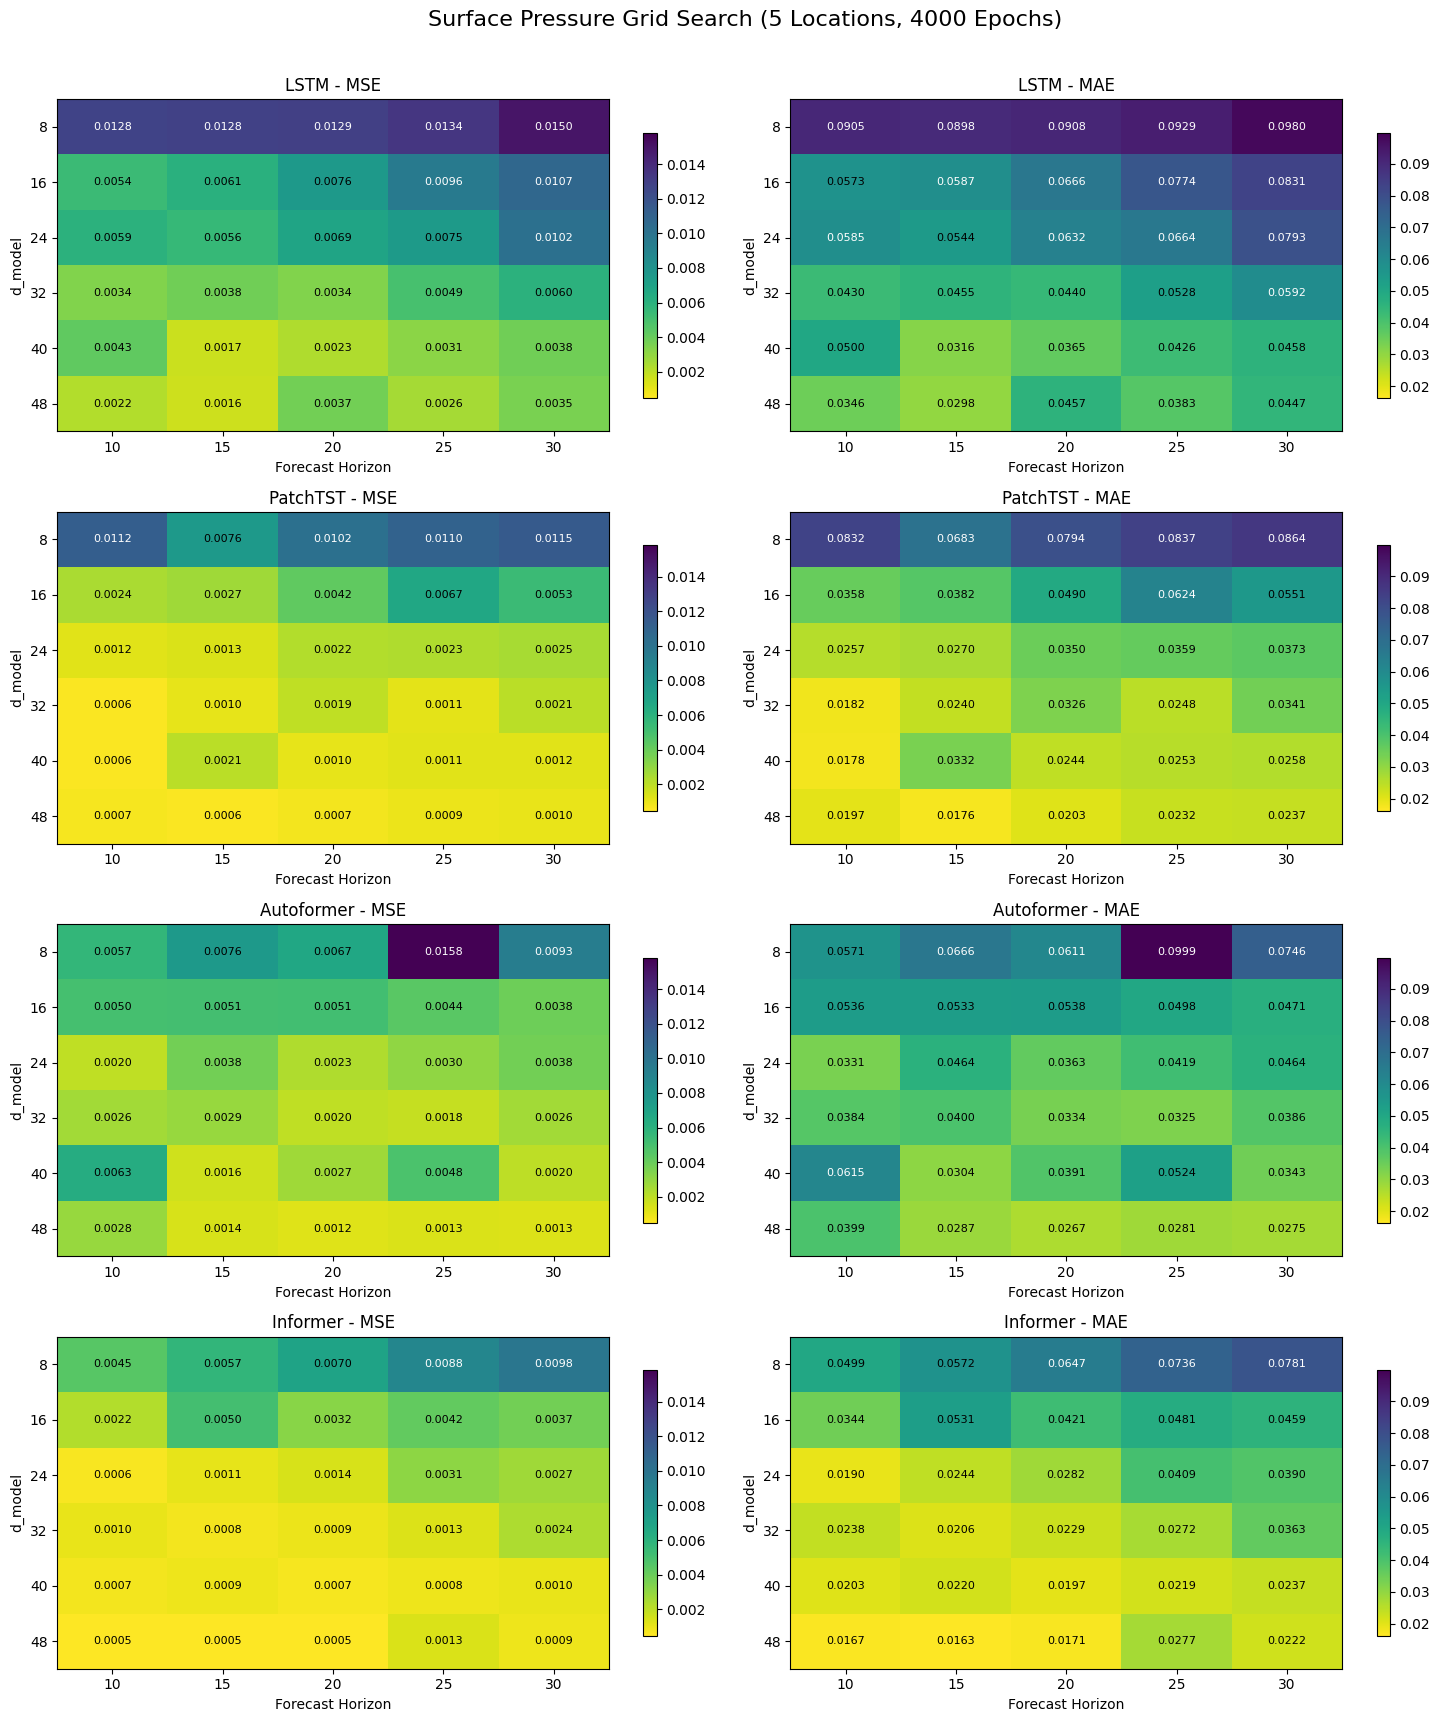


=== BEST MSE PER MODEL ===
     Model  PatchLen  Horizon  d_model      MSE      MAE
  Informer       120       15       48 0.000474 0.016267
  PatchTST       120       15       48 0.000554 0.017573
Autoformer       120       20       48 0.001223 0.026674
      LSTM       120       15       48 0.001626 0.029810


In [6]:
# Figure 5 — Surface Pressure Grid Search
results_dir = (
    results_root / "pressure_5channels_grid_e4000"
)

metrics_path = results_dir / "metrics.csv"

if not metrics_path.is_file():
    raise FileNotFoundError(metrics_path)

metrics = pd.read_csv(metrics_path)

model_names = ["LSTM", "PatchTST", "Autoformer", "Informer"]
d_models = [8, 16, 24, 32, 40, 48]
horizons = [10, 15, 20, 25, 30]
metric_names = ["MSE", "MAE"]

# 2. Verify all 120 configurations
expected = {
    (m, d, h)
    for m in model_names
    for d in d_models
    for h in horizons
}

actual = set(zip(
    metrics["Model"],
    metrics["d_model"],
    metrics["Horizon"]
))

assert len(metrics) == 120, f"Expected 120 rows, got {len(metrics)}"
assert actual == expected, f"Missing configurations: {expected - actual}"
assert (metrics["PatchLen"] == 120).all()
assert metrics[metric_names].notna().all().all()

checkpoints = list(results_dir.glob("*_p120_h*_d*.pt"))
assert len(checkpoints) == 120, (
    f"Expected 120 checkpoints, found {len(checkpoints)}"
)

print("=== SURFACE PRESSURE: 4000 EPOCHS ===")
print("Metrics:", metrics_path)
print("Total runs:", len(metrics))
print("Checkpoints:", len(checkpoints))

# 3. Shared color scales across models
scales = {
    metric: (metrics[metric].min(), metrics[metric].max())
    for metric in metric_names
}

fig, axes = plt.subplots(4, 2, figsize=(15, 17))

# 4. Plot MSE and MAE
for row, model_name in enumerate(model_names):
    model_data = metrics[metrics["Model"] == model_name]

    for col, metric_name in enumerate(metric_names):
        ax = axes[row, col]

        heatmap_data = model_data.pivot(
            index="d_model",
            columns="Horizon",
            values=metric_name
        ).reindex(index=d_models, columns=horizons)

        values = heatmap_data.to_numpy()
        vmin, vmax = scales[metric_name]

        im = ax.imshow(
            values,
            cmap="viridis_r",
            aspect="auto",
            vmin=vmin,
            vmax=vmax
        )

        for i in range(len(d_models)):
            for j in range(len(horizons)):
                value = values[i, j]

                ax.text(
                    j, i, f"{value:.4f}",
                    ha="center",
                    va="center",
                    fontsize=8,
                    color="white" if im.norm(value) > 0.5 else "black"
                )

        ax.set_xticks(range(len(horizons)), horizons)
        ax.set_yticks(range(len(d_models)), d_models)

        ax.set_xlabel("Forecast Horizon")
        ax.set_ylabel("d_model")
        ax.set_title(f"{model_name} - {metric_name}")

        fig.colorbar(im, ax=ax, shrink=0.8)

fig.suptitle(
    "Surface Pressure Grid Search (5 Locations, 4000 Epochs)",
    fontsize=16, y=1.01
)

plt.tight_layout()

save_path = results_dir / "figure5_pressure_heatmaps_5channels_e4000.png"

safe_save_figure(
    fig,
    "figure5_pressure_heatmaps.png"
)

plt.show()

# 5. Best configuration of each model
print("\n=== BEST MSE PER MODEL ===")

best = (
    metrics.loc[metrics.groupby("Model")["MSE"].idxmin()]
    [["Model", "PatchLen", "Horizon", "d_model", "MSE", "MAE"]]
    .sort_values("MSE")
)

print(best.to_string(index=False))

## Figure 6 — Surface Pressure Forecasting

Hình so sánh dự báo Surface Pressure của bốn mô hình tại năm vị trí không gian.

Cấu hình:

- Patch length: 120.
- Forecast horizon: 15.
- `d_model = 8`.
- Epochs: 4000.
- Input channels: 5.

Các checkpoint nằm trong:

`results/pressure_5channels_figure6_e4000/`

Hình lấy bước dự báo đầu tiên của mỗi cửa sổ trượt, đồng thời so sánh với Ground Truth.

Chỉ sử dụng kết quả thí nghiệm Surface Pressure năm kênh, không sử dụng checkpoint của nhánh bốn kênh cũ.

LSTM         MSE=0.012755 MAE=0.089925
PatchTST     MSE=0.008960 MAE=0.074818
Autoformer   MSE=0.006107 MAE=0.058700
Informer     MSE=0.007951 MAE=0.070404
Saved: c:\Users\Win 11 New\Desktop\pa gk\experiments\02_climate\figures\figure6_pressure_forecasting.png


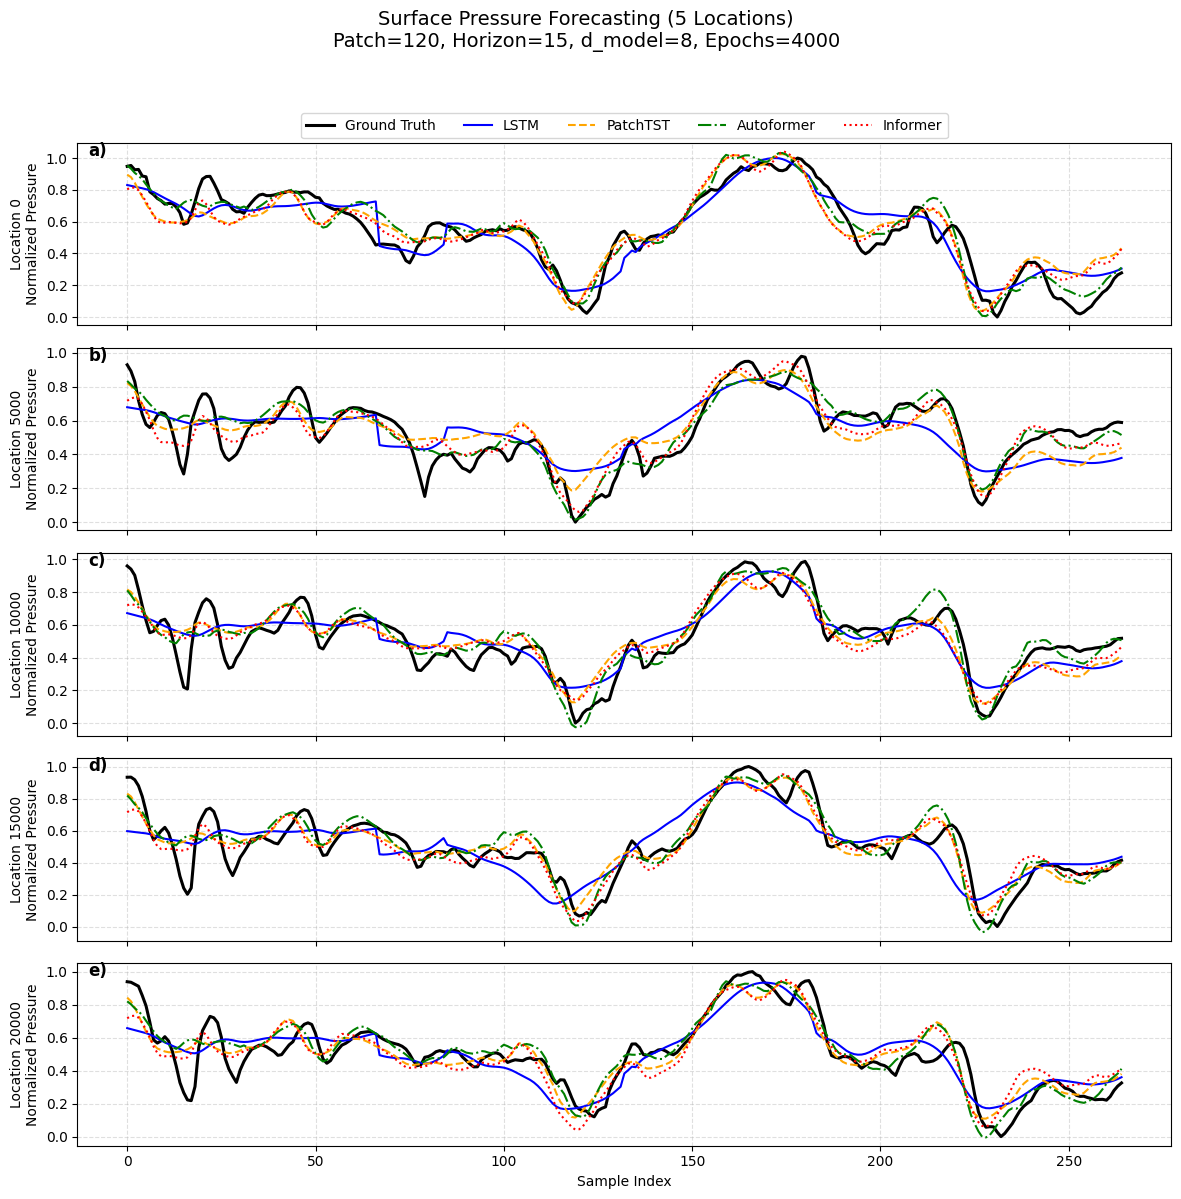


Samples: 265


In [7]:
# Figure 6 — Surface Pressure Forecasting
results_dir = (
    results_root / "pressure_5channels_figure6_e4000"
)

# 2. Figure 6 configuration
P, H, D = 120, 15, 8
location_indices = [0, 5000, 10000, 15000, 20000]
F = len(location_indices)

assert F == 5

model_names = ["LSTM", "PatchTST", "Autoformer", "Informer"]
results = {}

# 3. Load saved checkpoints
for name in model_names:
    path = results_dir / f"{name.lower()}_p{P}_h{H}_d{D}.pt"

    if not path.is_file():
        raise FileNotFoundError(path)

    ckpt = load_checkpoint(path)

    assert ckpt["epochs"] == 4000
    assert ckpt["patch_len"] == P
    assert ckpt["horizon"] == H
    assert ckpt["d_model"] == D
    assert ckpt["input_dim"] == F

    results[name] = ckpt

    print(
        f"{name:<12} "
        f"MSE={ckpt['mse']:.6f} "
        f"MAE={ckpt['mae']:.6f}"
    )

# 4. Prepare ground truth and predictions
truth_tensor = results["LSTM"]["truth"]
N = truth_tensor.shape[0]
assert N == 265
assert truth_tensor.shape == (265, 75)

assert truth_tensor.shape == (N, F * H)

# lấy bước forecast đầu tiên của mỗi sample
ground_truth = (
    truth_tensor.detach().cpu().numpy()
    .reshape(N, F, H)[:, :, 0]
)

predictions = {}

for name, ckpt in results.items():
    assert ckpt["pred"].shape == (N, F * H)

    assert torch.allclose(
        ckpt["truth"], truth_tensor,
        atol=1e-6, rtol=1e-6
    ), f"Ground truth mismatch: {name}"

    predictions[name] = (
        ckpt["pred"].detach().cpu().numpy()
        .reshape(N, F, H)[:, :, 0]
    )

# 5. Plot Figure 6
styles = {
    "LSTM":       {"color": "blue", "linestyle": "-"},
    "PatchTST":   {"color": "orange", "linestyle": "--"},
    "Autoformer": {"color": "green", "linestyle": "-."},
    "Informer":   {"color": "red", "linestyle": ":"}
}

fig, axes = plt.subplots(
    F, 1, figsize=(12, 12), sharex=True
)

for site, ax in enumerate(axes):

    ax.plot(
        np.arange(N),
        ground_truth[:, site],
        color="black",
        linewidth=2.2,
        label="Ground Truth"
    )

    for name in model_names:
        ax.plot(
            np.arange(N),
            predictions[name][:, site],
            linewidth=1.5,
            label=name,
            **styles[name]
        )

    ax.set_ylabel(
        f"Location {location_indices[site]}\nNormalized Pressure"
    )

    ax.grid(True, linestyle="--", alpha=0.4)

    ax.text(
        0.01, 0.93,
        f"{chr(97 + site)})",
        transform=ax.transAxes,
        fontsize=12,
        fontweight="bold"
    )

axes[0].legend(
    ncol=5,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.20)
)

axes[-1].set_xlabel("Sample Index")

fig.suptitle(
    "Surface Pressure Forecasting (5 Locations)\n"
    "Patch=120, Horizon=15, d_model=8, Epochs=4000",
    fontsize=14,
    y=0.995
)

plt.tight_layout(rect=[0, 0, 1, 0.965])

save_path = results_dir / "figure6_pressure_5channels_e4000.png"

safe_save_figure(
    fig,
    "figure6_pressure_forecasting.png"
)

plt.show()

print("\nSamples:", N)

## Figure 7 — ERA5 Wind Speed Forecasting

Hình so sánh dự báo tốc độ gió tại 10 địa điểm thuộc nước Đức trên bộ dữ liệu ERA5.

Các mô hình:

- LSTM.
- PatchTST kết hợp Koopman.
- Autoformer kết hợp Koopman.
- Informer kết hợp Koopman.

Cấu hình:

- Patch length: 120.
- Forecast horizon: 30.
- `d_model = 48`.
- Epochs: 4000.
- Số kênh: 10.

Dữ liệu lấy từ bốn checkpoint thuộc `era5_wind_e4000`.

Hình hiển thị bước dự báo đầu tiên của mỗi cửa sổ trượt.

Các metric trong thực nghiệm này được tính trên những cửa sổ đã sử dụng để huấn luyện, không phải tập Test riêng.

LSTM         MSE=0.003387 MAE=0.044388
PatchTST     MSE=0.002596 MAE=0.039073
Autoformer   MSE=0.003411 MAE=0.044773
Informer     MSE=0.002664 MAE=0.039703
Saved: c:\Users\Win 11 New\Desktop\pa gk\experiments\02_climate\figures\figure7_era5_forecasting.png


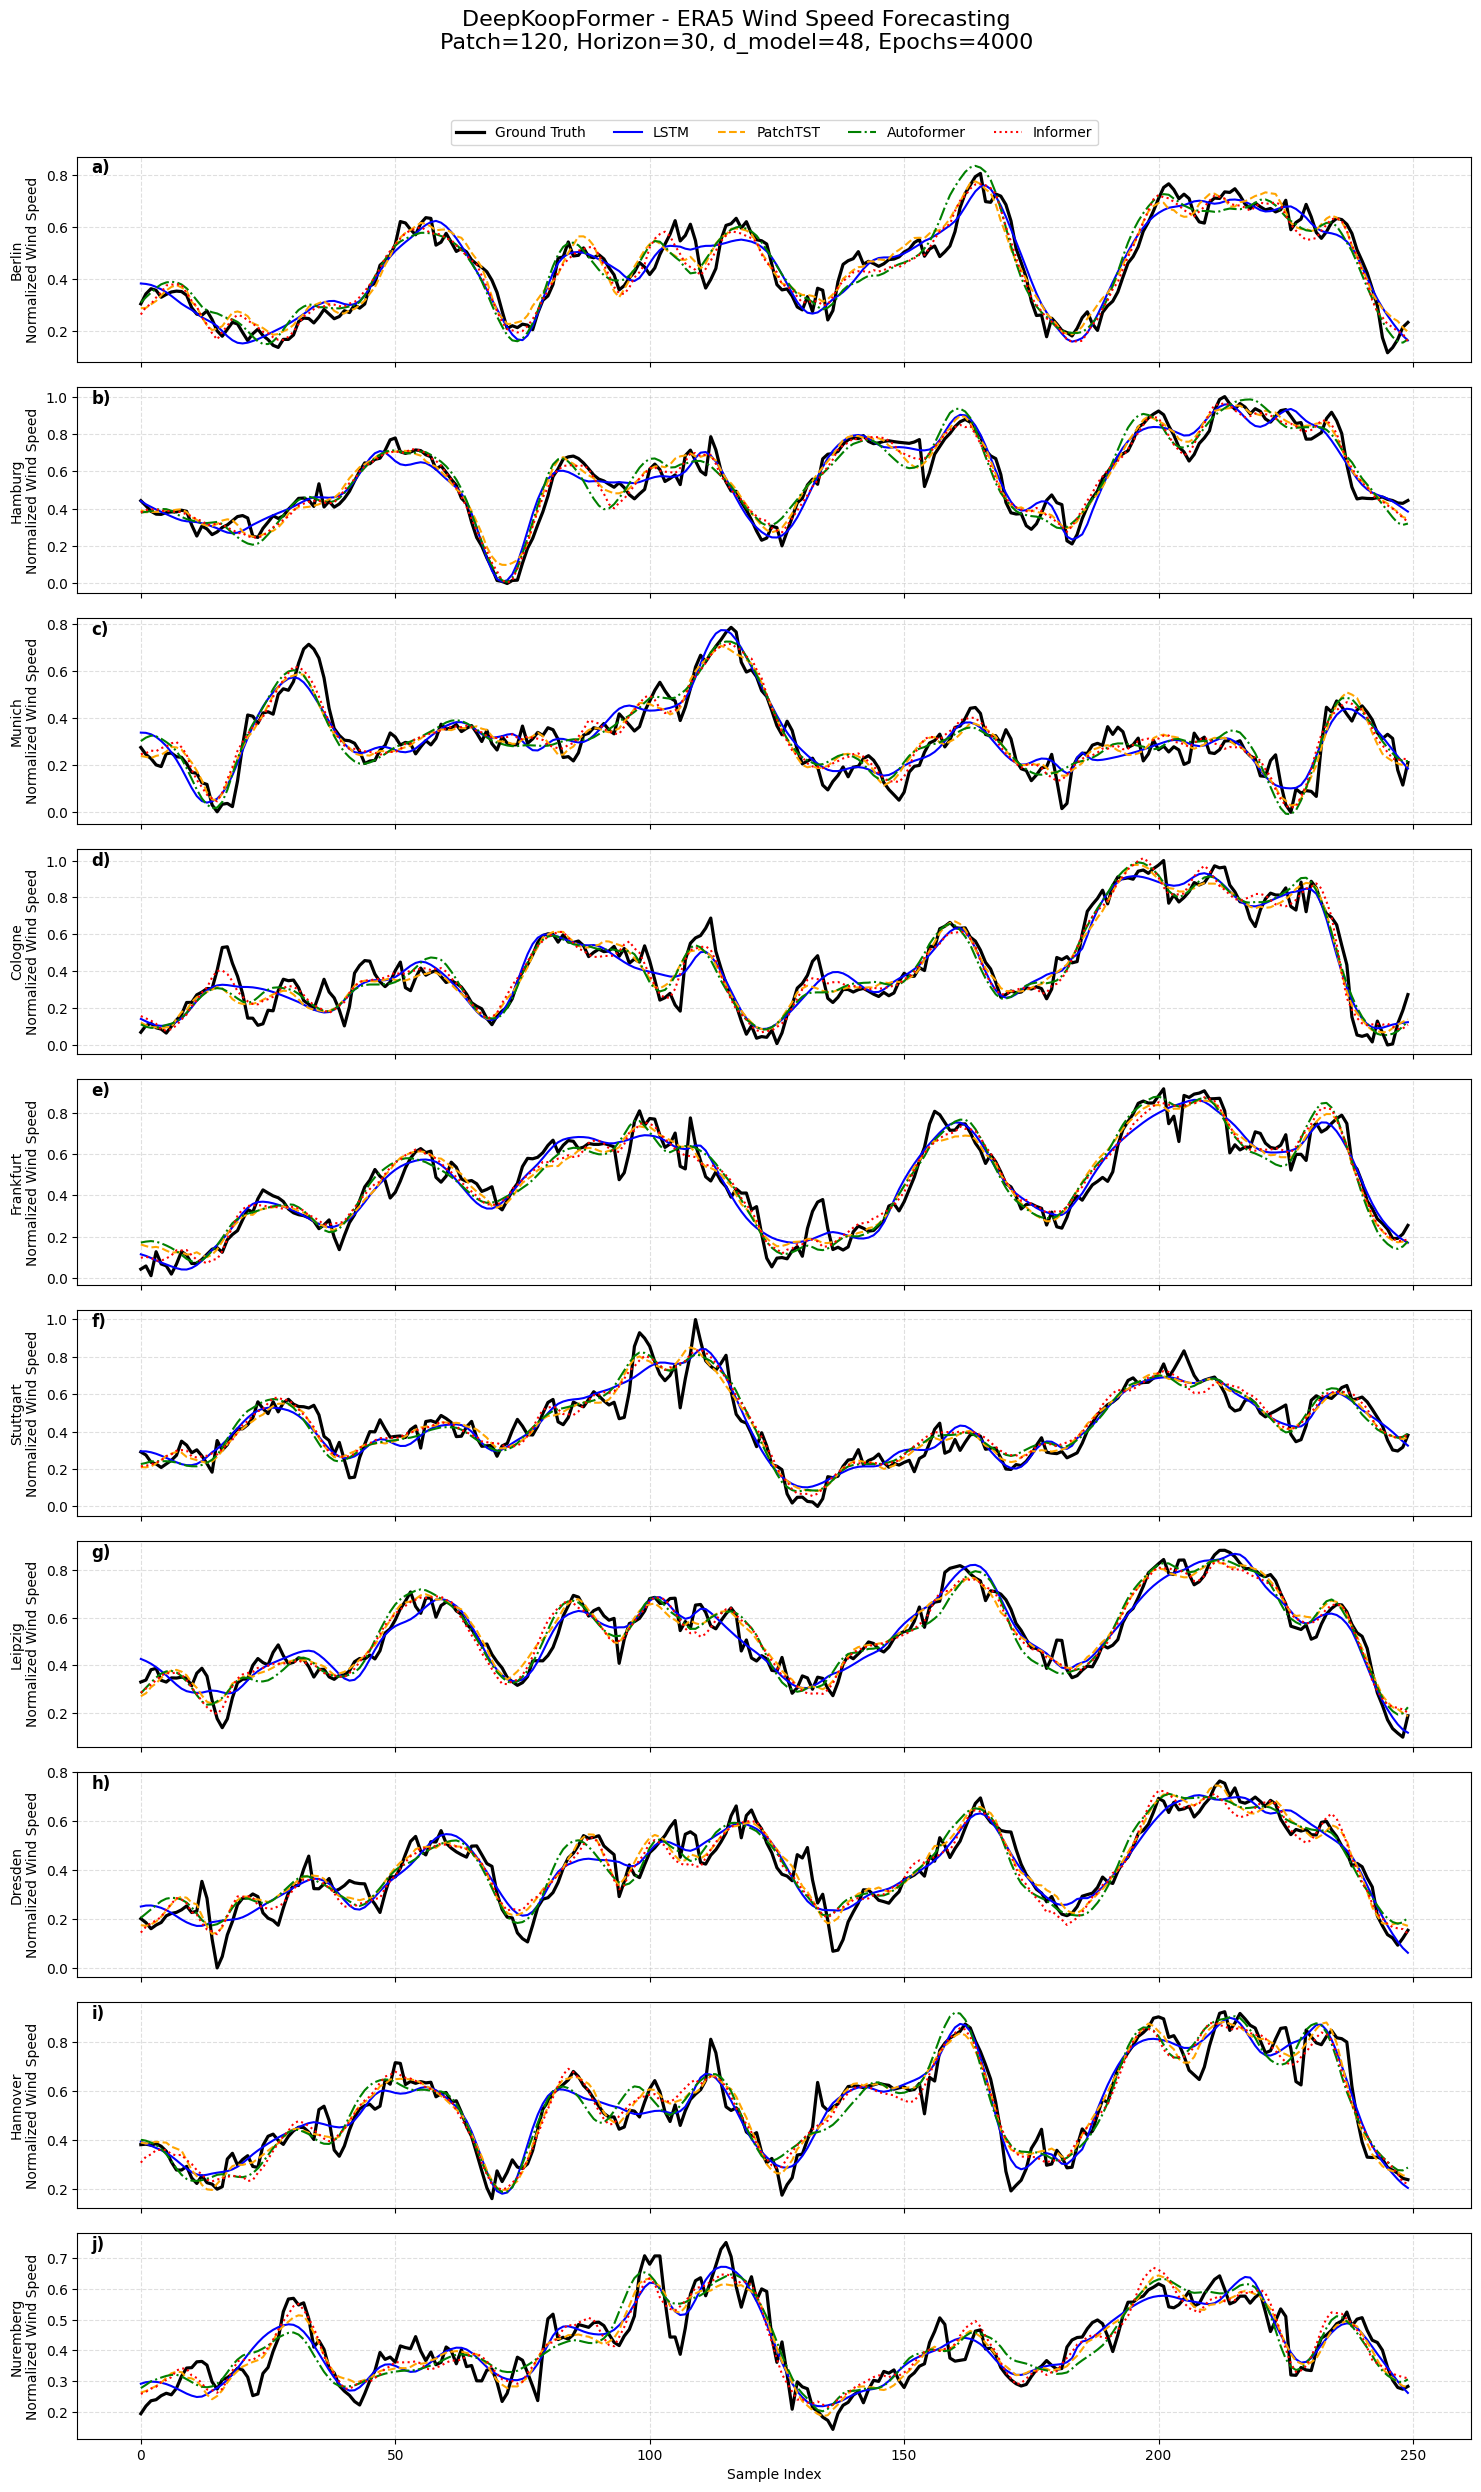


Samples: 250
Locations: 10


In [8]:
# Figure 7 — ERA5 Wind Speed Forecasting
results_dir = results_root / "era5_wind_e4000"

# 2. Figure 7 configuration
P, H, D = 120, 30, 48
model_names = ["LSTM", "PatchTST", "Autoformer", "Informer"]

# 3. Load trained checkpoints
results = {}

for name in model_names:
    path = results_dir / f"{name.lower()}_p{P}_h{H}_d{D}.pt"

    if not path.is_file():
        raise FileNotFoundError(path)

    ckpt = load_checkpoint(path)

    assert ckpt["epochs"] == 4000
    assert ckpt["patch_len"] == P
    assert ckpt["horizon"] == H
    assert ckpt["d_model"] == D
    assert ckpt["input_dim"] == 10

    results[name] = ckpt

    print(
        f"{name:<12} "
        f"MSE={ckpt['mse']:.6f} "
        f"MAE={ckpt['mae']:.6f}"
    )

# 4. Prepare Ground Truth and predictions
truth_tensor = results["LSTM"]["truth"]
N = truth_tensor.shape[0]
F = 10

assert truth_tensor.shape == (250, F * H)

location_names = results["LSTM"]["location_names"]

# Forecast step 0, following the author's plotting convention
ground_truth = (
    truth_tensor.numpy()
    .reshape(N, F, H)[:, :, 0]
)

predictions = {}

for name, ckpt in results.items():
    assert torch.allclose(
        ckpt["truth"], truth_tensor,
        atol=1e-6, rtol=1e-6
    ), f"Ground Truth mismatch: {name}"

    predictions[name] = (
        ckpt["pred"].numpy()
        .reshape(N, F, H)[:, :, 0]
    )

# 5. Plot all 10 locations
styles = {
    "LSTM": {
        "color": "blue",
        "linestyle": "-"
    },
    "PatchTST": {
        "color": "orange",
        "linestyle": "--"
    },
    "Autoformer": {
        "color": "green",
        "linestyle": "-."
    },
    "Informer": {
        "color": "red",
        "linestyle": ":"
    }
}

fig, axes = plt.subplots(
    F, 1,
    figsize=(15, 25),
    sharex=True
)

for site, ax in enumerate(axes):

    ax.plot(
        np.arange(N),
        ground_truth[:, site],
        color="black",
        linewidth=2.3,
        label="Ground Truth"
    )

    for name in model_names:
        ax.plot(
            np.arange(N),
            predictions[name][:, site],
            linewidth=1.5,
            label=name,
            **styles[name]
        )

    ax.set_ylabel(
        f"{location_names[site]}\nNormalized Wind Speed"
    )

    ax.grid(
        True,
        linestyle="--",
        alpha=0.4
    )

    ax.text(
        0.01, 0.92,
        f"{chr(97 + site)})",
        transform=ax.transAxes,
        fontsize=12,
        fontweight="bold"
    )

axes[0].legend(
    ncol=5,
    loc="lower center",
    bbox_to_anchor=(0.5, 1.02)
)

axes[-1].set_xlabel("Sample Index")

fig.suptitle(
    "DeepKoopFormer - ERA5 Wind Speed Forecasting\n"
    "Patch=120, Horizon=30, d_model=48, Epochs=4000",
    fontsize=16,
    y=0.995
)

plt.tight_layout(rect=[0, 0, 1, 0.98])

# 6. Save figure
save_path = results_dir / "figure7_era5_forecasting_e4000.png"

safe_save_figure(
    fig,
    "figure7_era5_forecasting.png"
)

plt.show()

print("\nSamples:", N)
print("Locations:", F)


## Phân tích bổ sung — ERA5 Training

Phần này gồm ba biểu đồ phân tích quá trình huấn luyện trên dữ liệu ERA5:

1. **Training Loss:** sự thay đổi của hàm mất mát theo epoch.
2. **Koopman Stability:** diễn biến chỉ số `max(sigmoid(S_raw))` của các mô hình Koopman.
3. **MSE/MAE Comparison:** so sánh sai số cuối cùng của bốn mô hình.

Các giá trị được đọc trực tiếp từ checkpoint đã lưu.

Chỉ số Koopman đang biểu diễn tham số hóa giá trị kỳ dị, không phải kết quả tính trực tiếp trị riêng lớn nhất của ma trận Koopman.

Các metric MSE và MAE được tính trên dữ liệu huấn luyện đã chuẩn hóa.

Saved: c:\Users\Win 11 New\Desktop\pa gk\experiments\02_climate\figures\era5_training_loss.png


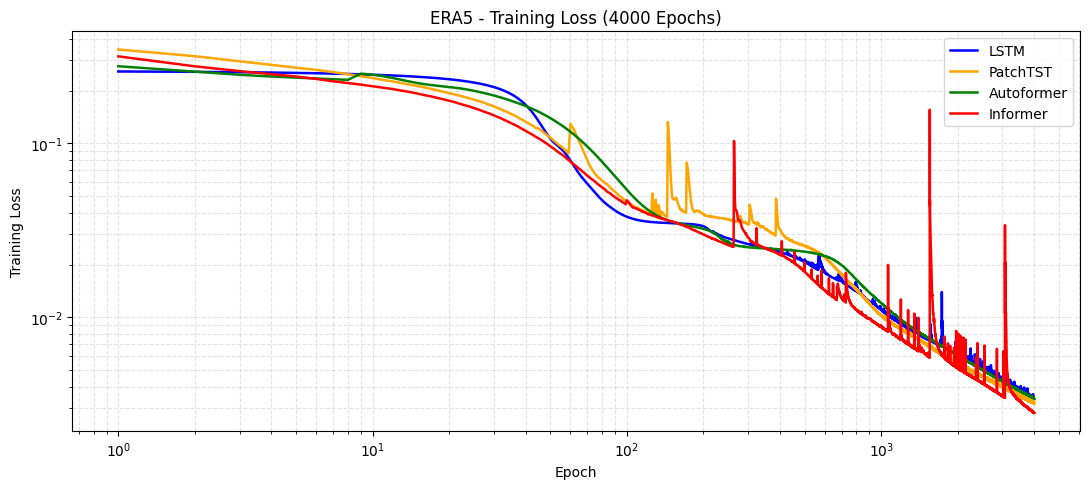

Saved: c:\Users\Win 11 New\Desktop\pa gk\experiments\02_climate\figures\era5_koopman_stability.png


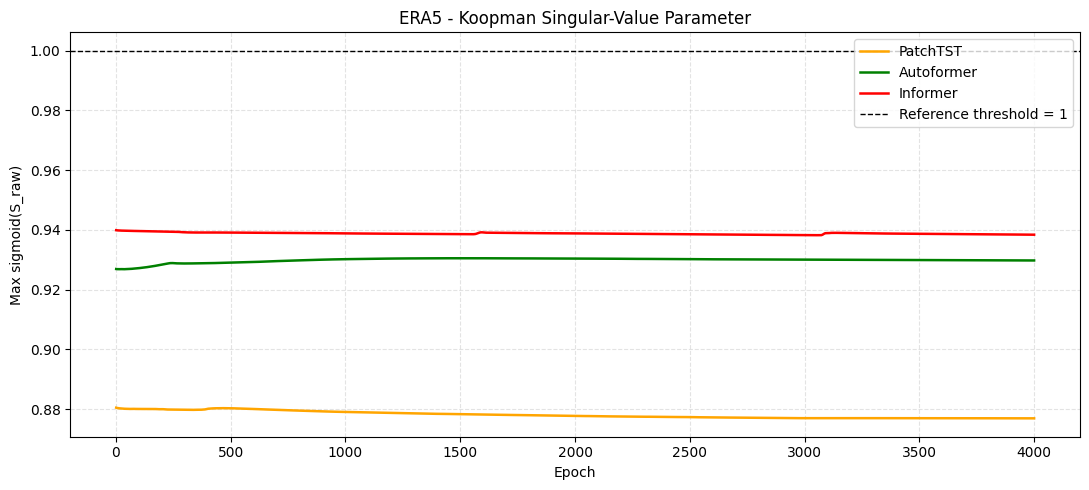

Saved: c:\Users\Win 11 New\Desktop\pa gk\experiments\02_climate\figures\era5_metrics_comparison.png


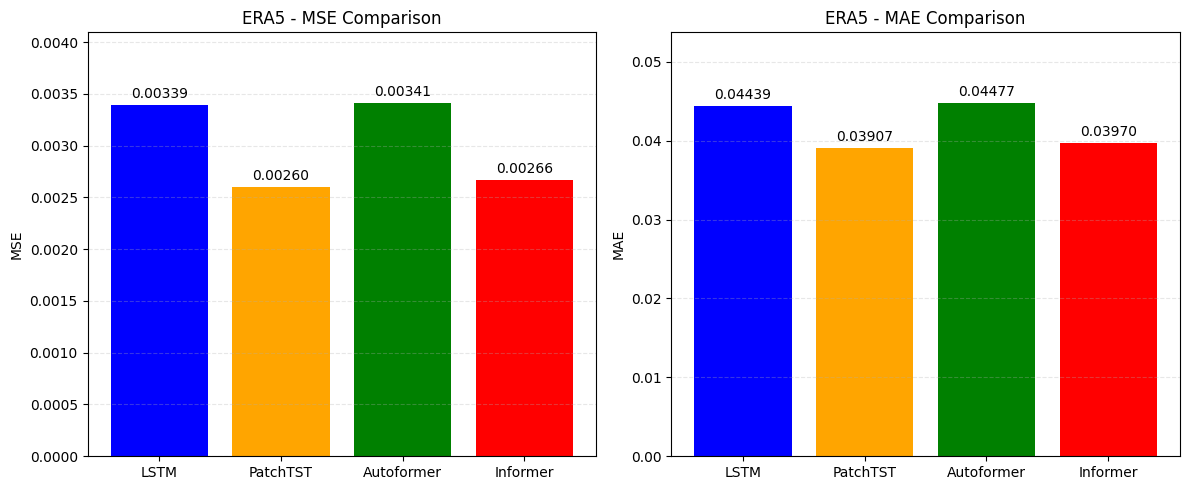


=== ERA5 MODEL COMPARISON ===
     Model      MSE      MAE
  PatchTST 0.002596 0.039073
  Informer 0.002664 0.039703
      LSTM 0.003387 0.044388
Autoformer 0.003411 0.044773


In [ ]:
# 1. Đọc độc lập bốn checkpoint ERA5
era5_results_dir = results_root / "era5_wind_e4000"

era5_results = {
    name: load_checkpoint(
        era5_results_dir / f"{name.lower()}_p120_h30_d48.pt"
    )
    for name in MODELS
}

colors = {
    "LSTM": "blue",
    "PatchTST": "orange",
    "Autoformer": "green",
    "Informer": "red"
}


# ==================================================
# 2. ERA5 — Training Loss
# ==================================================
fig, ax = plt.subplots(figsize=(11, 5))

for name in MODELS:
    loss = era5_results[name]["loss"].numpy()
    epoch_axis = np.arange(1, len(loss) + 1)

    assert len(loss) == 4000

    ax.plot(
        epoch_axis,
        loss,
        label=name,
        color=colors[name],
        linewidth=1.8
    )

ax.set_xscale("log")
ax.set_yscale("log")

ax.set_xlabel("Epoch")
ax.set_ylabel("Training Loss")
ax.set_title("ERA5 - Training Loss (4000 Epochs)")

ax.grid(
    True, which="both",
    linestyle="--", alpha=0.35
)

ax.legend()
plt.tight_layout()

safe_save_figure(
    fig,
    "era5_training_loss.png"
)

plt.show()


# ==================================================
# 3. ERA5 — Koopman Stability
# ==================================================
fig, ax = plt.subplots(figsize=(11, 5))

for name in ["PatchTST", "Autoformer", "Informer"]:
    eig = era5_results[name]["eig"].numpy()

    assert len(eig) == 4000

    ax.plot(
        np.arange(1, len(eig) + 1),
        eig,
        label=name,
        color=colors[name],
        linewidth=1.8
    )

ax.axhline(
    y=1.0,
    color="black",
    linestyle="--",
    linewidth=1,
    label="Reference threshold = 1"
)

ax.set_xlabel("Epoch")
ax.set_ylabel("Max sigmoid(S_raw)")

ax.set_title(
    "ERA5 - Koopman Singular-Value Parameter"
)

ax.grid(True, linestyle="--", alpha=0.35)
ax.legend()

plt.tight_layout()

safe_save_figure(
    fig,
    "era5_koopman_stability.png"
)

plt.show()

# 4. ERA5 — MSE/MAE Comparison
era5_metrics = pd.DataFrame([
    {
        "Model": name,
        "MSE": era5_results[name]["mse"],
        "MAE": era5_results[name]["mae"]
    }
    for name in MODELS
])

fig, axes = plt.subplots(
    1, 2, figsize=(12, 5)
)

for ax, metric in zip(axes, ["MSE", "MAE"]):
    bars = ax.bar(
        era5_metrics["Model"],
        era5_metrics[metric],
        color=[colors[name] for name in MODELS]
    )

    ax.bar_label(
        bars, fmt="%.5f", padding=3
    )

    ax.set_ylabel(metric)
    ax.set_title(f"ERA5 - {metric} Comparison")

    ax.set_ylim(
        0,
        era5_metrics[metric].max() * 1.2
    )

    ax.grid(
        axis="y",
        linestyle="--",
        alpha=0.3
    )

plt.tight_layout()

safe_save_figure(
    fig,
    "era5_metrics_comparison.png"
)

plt.show()


# 5. Bảng tổng hợp metric
print("\n=== ERA5 MODEL COMPARISON ===")

print(
    era5_metrics
    .sort_values("MSE")
    .to_string(index=False)
)

## Figure 8 — Scenario 4: Train Heatmaps

Hình biểu diễn MSE và MAE trên tập Train của Scenario 4.

Không gian Grid Search:

- Patch lengths: 40, 50, 60, 70, 80, 90, 100.
- Forecast horizons: 2, 4, 6, 8, 10, 12, 14, 16.
- Bốn mô hình dự báo.
- `d_model = 48`.
- Epochs: 4000.

Hình có hai hàng và bốn cột.

- Hàng thứ nhất: MSE.
- Hàng thứ hai: MAE.
- Mỗi cột: một mô hình.

Dữ liệu được lấy từ 224 dòng Train trong `scenario4_train_test_e4000/metrics.csv`.

Các giá trị metric được tính trên dữ liệu đã chuẩn hóa Min-Max.

Saved: c:\Users\Win 11 New\Desktop\pa gk\experiments\02_climate\figures\figure8_train_heatmaps.png


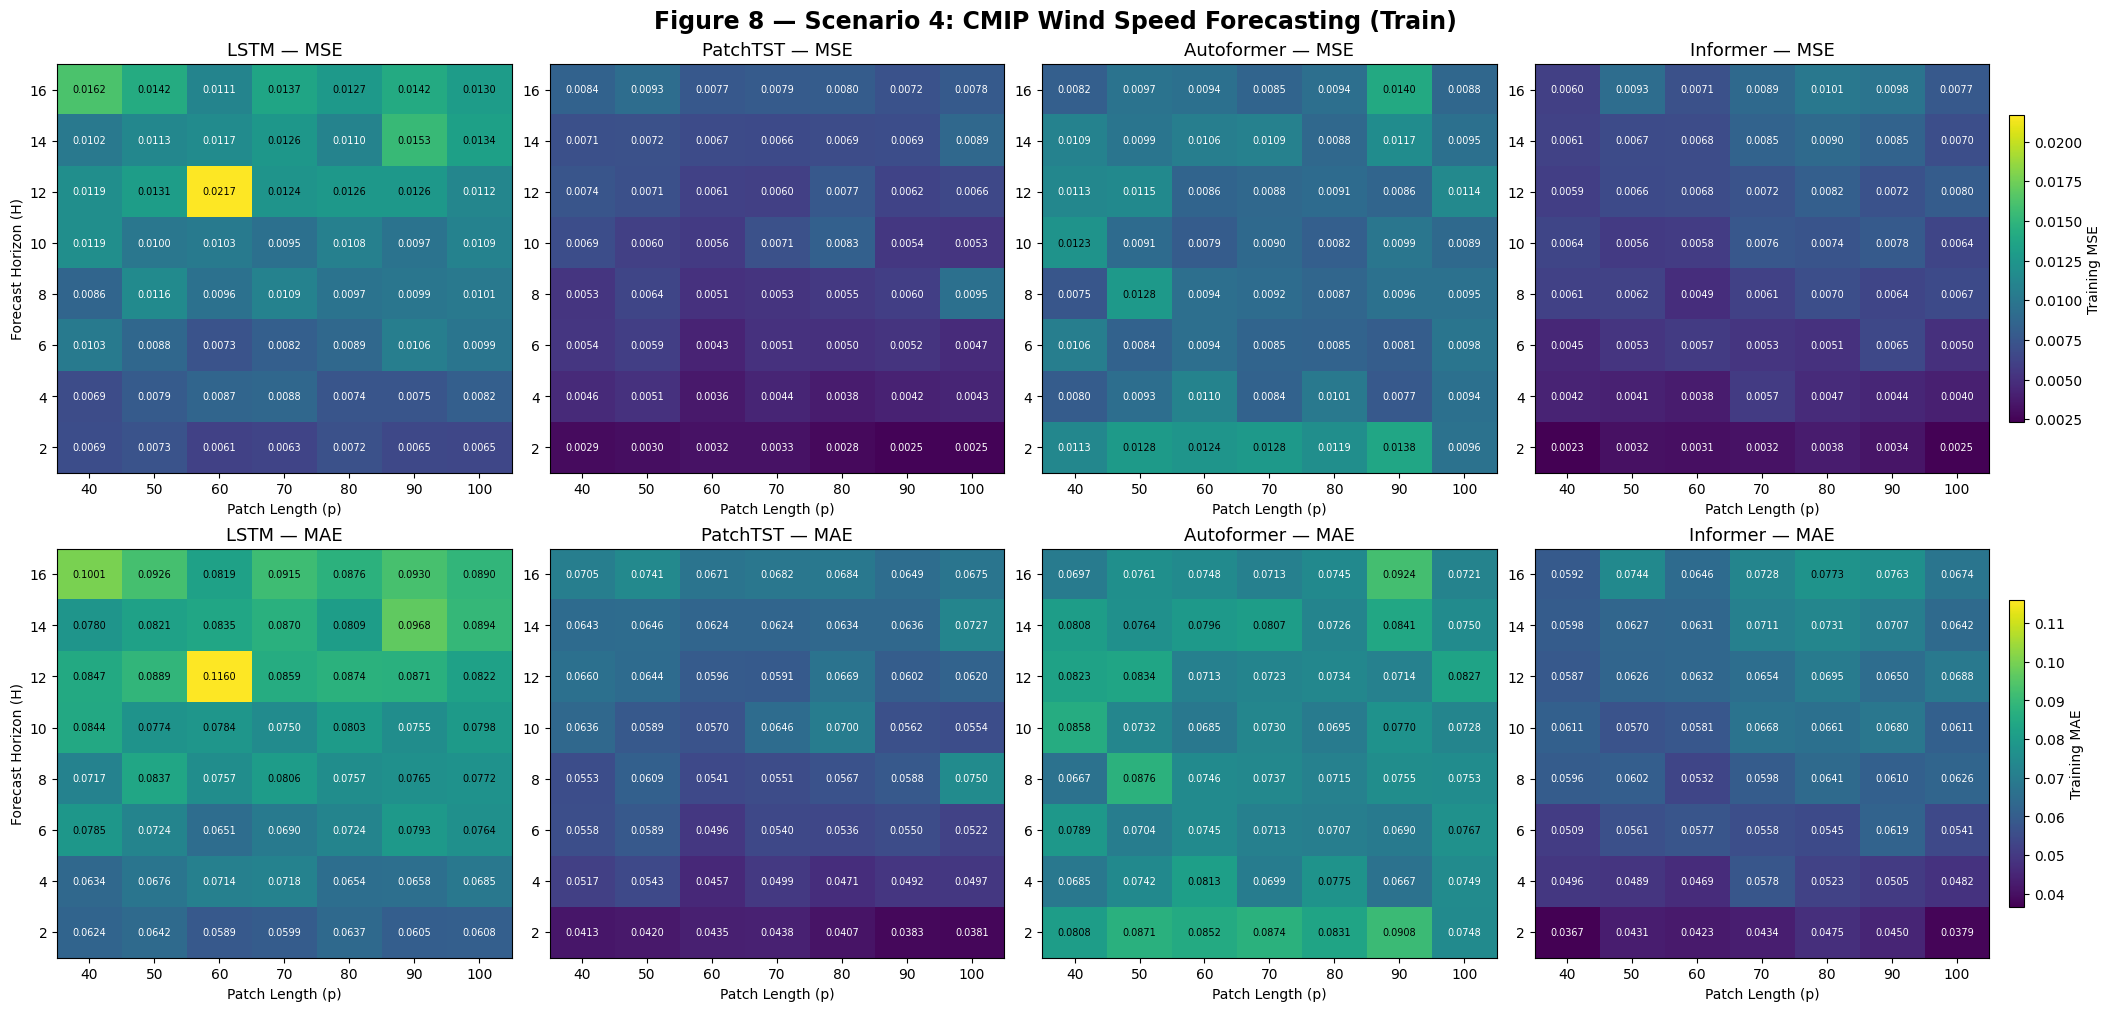

In [14]:
# 1. Lấy kết quả Train từ dữ liệu đã nạp ở cell đầu
train_df = scenario4_df[
    scenario4_df["Set"] == "Train"
].copy()

# 2. Cấu hình Grid Search Scenario 4
scenario4_models = ["LSTM", "PatchTST", "Autoformer", "Informer"]
scenario4_metrics = ["MSE", "MAE"]

scenario4_patch_lengths = [40, 50, 60, 70, 80, 90, 100]
scenario4_horizons = [2, 4, 6, 8, 10, 12, 14, 16]

assert len(train_df) == 224


# 3. Khởi tạo Figure: 2 metric x 4 mô hình
fig, axes = plt.subplots(
    2, 4,
    figsize=(21, 10),
    constrained_layout=True
)


# 4. Vẽ từng heatmap
for row, metric in enumerate(scenario4_metrics):

    # Dùng chung thang màu giữa bốn mô hình cho cùng metric
    vmin = train_df[metric].min()
    vmax = train_df[metric].max()

    for col, model in enumerate(scenario4_models):
        ax = axes[row, col]

        model_data = train_df[
            train_df["Model"] == model
        ]

        # Horizon x Patch Length
        pivot = model_data.pivot(
            index="Horizon",
            columns="PatchLen",
            values=metric
        ).reindex(
            index=scenario4_horizons,
            columns=scenario4_patch_lengths
        )

        values = pivot.to_numpy()

        assert values.shape == (8, 7)
        assert np.isfinite(values).all()

        # Vẽ heatmap
        im = ax.imshow(
            values,
            cmap="viridis",
            aspect="auto",
            origin="lower",
            vmin=vmin,
            vmax=vmax
        )

        # Tiêu đề từng biểu đồ con
        ax.set_title(
            f"{model} — {metric}",
            fontsize=13
        )

        # Nhãn trục
        ax.set_xticks(
            range(len(scenario4_patch_lengths)),
            scenario4_patch_lengths
        )

        ax.set_yticks(
            range(len(scenario4_horizons)),
            scenario4_horizons
        )

        ax.set_xlabel("Patch Length (p)")

        if col == 0:
            ax.set_ylabel("Forecast Horizon (H)")

        # Hiển thị giá trị MSE/MAE trong từng ô
        for i in range(len(scenario4_horizons)):
            for j in range(len(scenario4_patch_lengths)):
                value = values[i, j]

                ax.text(
                    j, i,
                    f"{value:.4f}",
                    ha="center",
                    va="center",
                    fontsize=7,
                    color=(
                        "white"
                        if value < (vmin + vmax) / 2
                        else "black"
                    )
                )

    # Một colorbar chung cho bốn mô hình
    fig.colorbar(
        im,
        ax=axes[row, :],
        shrink=0.75,
        pad=0.01,
        label=f"Training {metric}"
    )


# 5. Tiêu đề chung
fig.suptitle(
    "Figure 8 — Scenario 4: "
    "CMIP Wind Speed Forecasting (Train)",
    fontsize=17,
    fontweight="bold"
)


# 6. Lưu Figure 8 vào thư mục figures/
safe_save_figure(
    fig,
    "figure8_train_heatmaps.png"
)

plt.show()

## Figure 9 — Scenario 4: Test Heatmaps

Hình biểu diễn MSE và MAE trên tập Test của Scenario 4.

Cấu hình Grid Search giống Figure 8:

- Bảy patch length.
- Tám forecast horizon.
- Bốn mô hình.
- Tổng cộng 224 cấu hình.

Hình sử dụng 224 dòng Test trong `metrics.csv`.

Tập Test là đoạn thời gian nằm sau tập Train. Các mô hình không cập nhật trọng số khi được đánh giá trên Test.

Figure 8 và Figure 9 có thang màu được xác định riêng. Vì vậy, khi so sánh hai hình cần dựa trên giá trị MSE/MAE thay vì chỉ dựa vào màu sắc.

Saved: c:\Users\Win 11 New\Desktop\pa gk\experiments\02_climate\figures\figure9_test_heatmaps.png


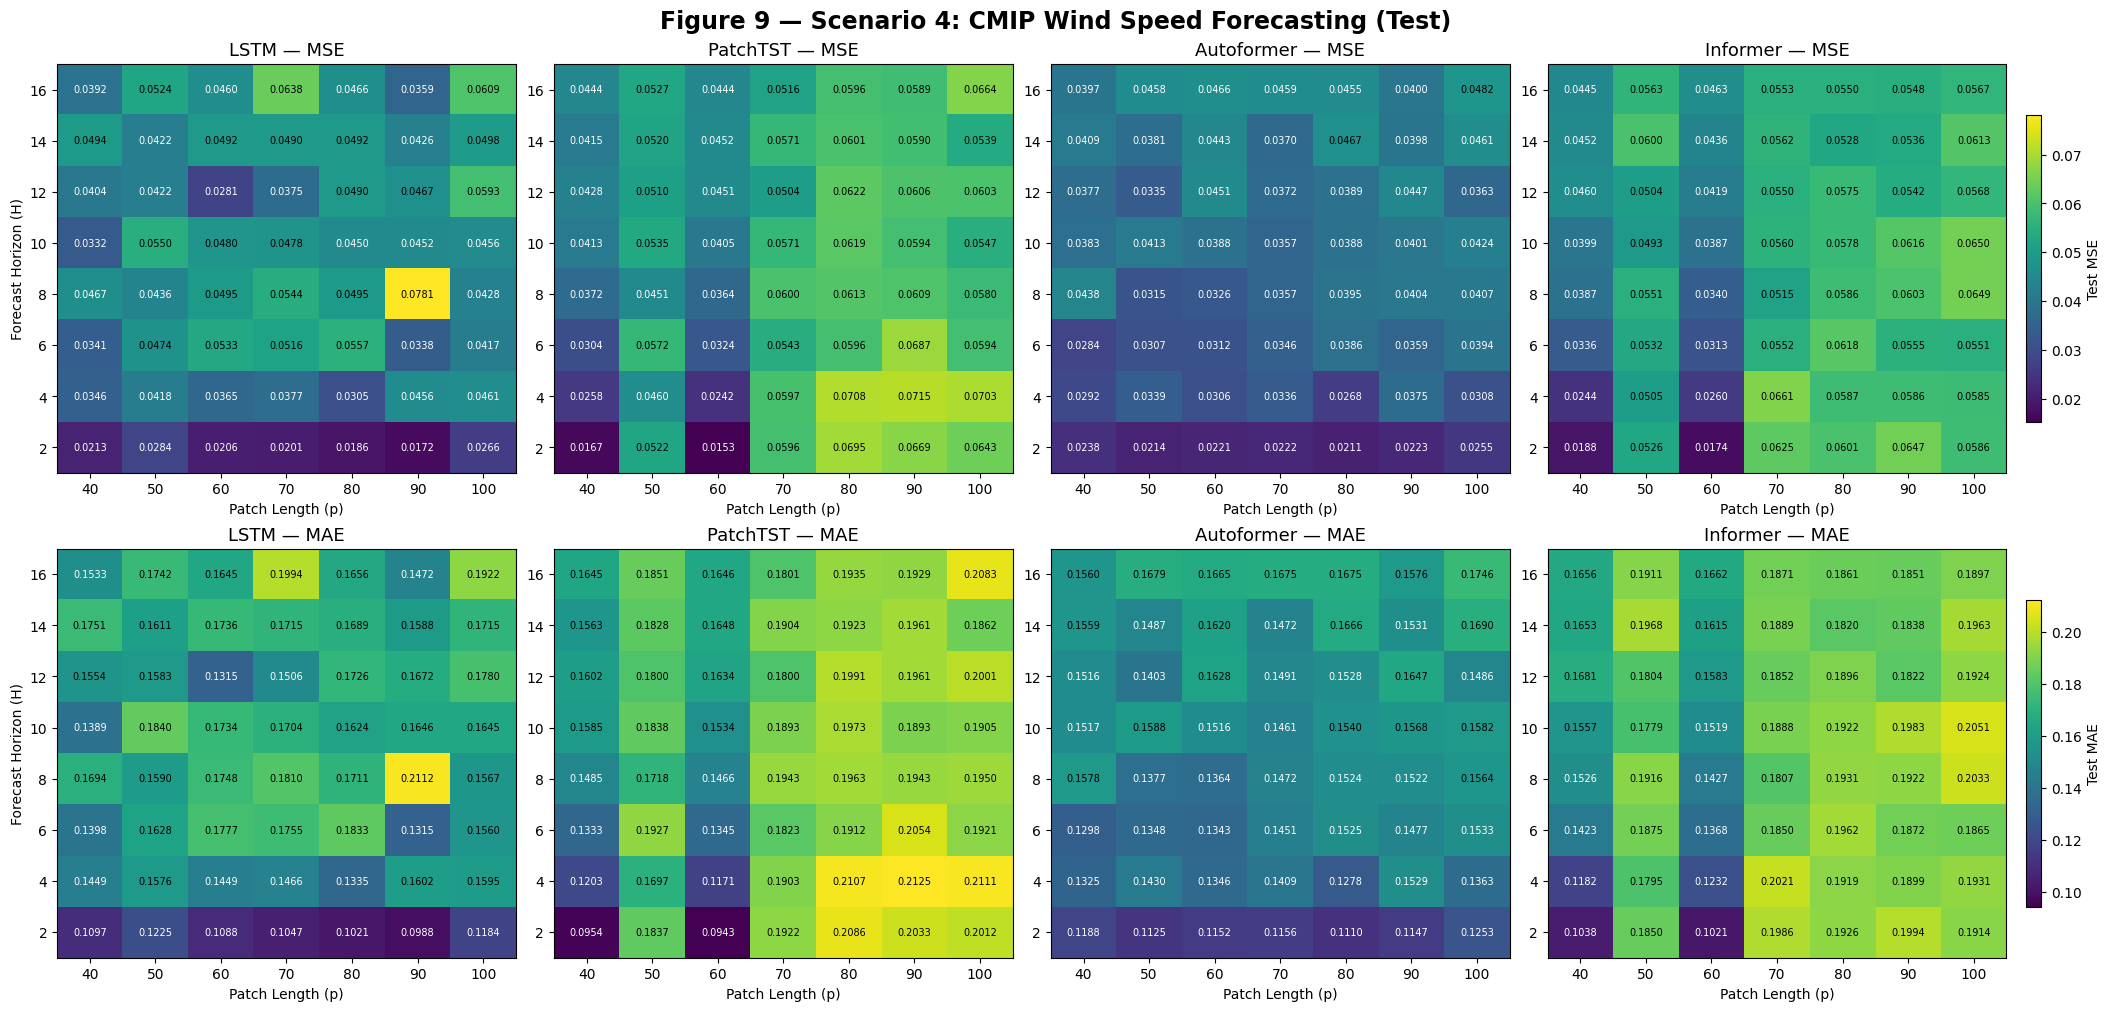

In [17]:
# 1. Lấy kết quả Test từ bảng metrics đã nạp
test_df = scenario4_df[
    scenario4_df["Set"] == "Test"
].copy()

# 2. Cấu hình Grid Search
models = ["LSTM", "PatchTST", "Autoformer", "Informer"]
metric_names = ["MSE", "MAE"]

patch_lengths = [40, 50, 60, 70, 80, 90, 100]
horizons = [2, 4, 6, 8, 10, 12, 14, 16]

# 3. Kiểm tra đầy đủ 224 kết quả Test
assert len(test_df) == 224

expected = {
    (model, p, h)
    for model in models
    for p in patch_lengths
    for h in horizons
}

actual = set(zip(
    test_df["Model"],
    test_df["PatchLen"],
    test_df["Horizon"]
))

assert actual == expected
assert not test_df.duplicated(
    ["Model", "PatchLen", "Horizon"]
).any()

assert np.isfinite(
    test_df[metric_names].to_numpy()
).all()


# 4. Tạo Figure gồm 2 hàng x 4 cột
fig, axes = plt.subplots(
    2, 4,
    figsize=(21, 10),
    constrained_layout=True
)


# 5. Vẽ heatmap
for row, metric in enumerate(metric_names):

    # Cùng một thang màu cho bốn mô hình
    vmin = test_df[metric].min()
    vmax = test_df[metric].max()

    for col, model in enumerate(models):
        ax = axes[row, col]

        model_data = test_df[
            test_df["Model"] == model
        ]

        # Trục dọc: Horizon
        # Trục ngang: Patch Length
        pivot = model_data.pivot(
            index="Horizon",
            columns="PatchLen",
            values=metric
        ).reindex(
            index=horizons,
            columns=patch_lengths
        )

        values = pivot.to_numpy()

        assert values.shape == (8, 7)
        assert np.isfinite(values).all()

        im = ax.imshow(
            values,
            cmap="viridis",
            aspect="auto",
            origin="lower",
            vmin=vmin,
            vmax=vmax
        )

        # Tiêu đề từng mô hình
        ax.set_title(
            f"{model} — {metric}",
            fontsize=13
        )

        # Nhãn trục
        ax.set_xticks(
            range(len(patch_lengths)),
            patch_lengths
        )

        ax.set_yticks(
            range(len(horizons)),
            horizons
        )

        ax.set_xlabel("Patch Length (p)")

        if col == 0:
            ax.set_ylabel("Forecast Horizon (H)")

        # Ghi giá trị MSE/MAE trong mỗi ô
        for i in range(len(horizons)):
            for j in range(len(patch_lengths)):
                value = values[i, j]

                ax.text(
                    j, i,
                    f"{value:.4f}",
                    ha="center",
                    va="center",
                    fontsize=7,
                    color=(
                        "white"
                        if value < (vmin + vmax) / 2
                        else "black"
                    )
                )

    # Colorbar dùng chung theo từng metric
    fig.colorbar(
        im,
        ax=axes[row, :],
        shrink=0.75,
        pad=0.01,
        label=f"Test {metric}"
    )


# 6. Tiêu đề toàn hình
fig.suptitle(
    "Figure 9 — Scenario 4: "
    "CMIP Wind Speed Forecasting (Test)",
    fontsize=17,
    fontweight="bold"
)


# 7. Lưu hình vào figures/
safe_save_figure(
    fig,
    "figure9_test_heatmaps.png"
)

plt.show()

## Figure 10 — Scenario 4: Test Forecasting

Hình so sánh dự báo của bốn mô hình với Ground Truth tại năm vị trí không gian của dữ liệu CMIP6 Wind.

Cấu hình:

- Patch length: 40.
- Forecast horizon: 8.
- `d_model = 48`.
- Epochs: 4000.
- Số kênh: 5.

Các vị trí:

`[0, 5000, 10000, 15000, 20000]`

Mỗi checkpoint có 456 cửa sổ Test, với 40 giá trị dự báo trên mỗi cửa sổ (5 kênh × 8 bước).

Hình sử dụng bước dự báo đầu tiên từ 250 cửa sổ Test liên tiếp đầu tiên.

Dự báo được đọc trực tiếp từ checkpoint đã lưu, không chạy lại mô hình.

Saved: c:\Users\Win 11 New\Desktop\pa gk\experiments\02_climate\figures\figure10_test_forecasts.png


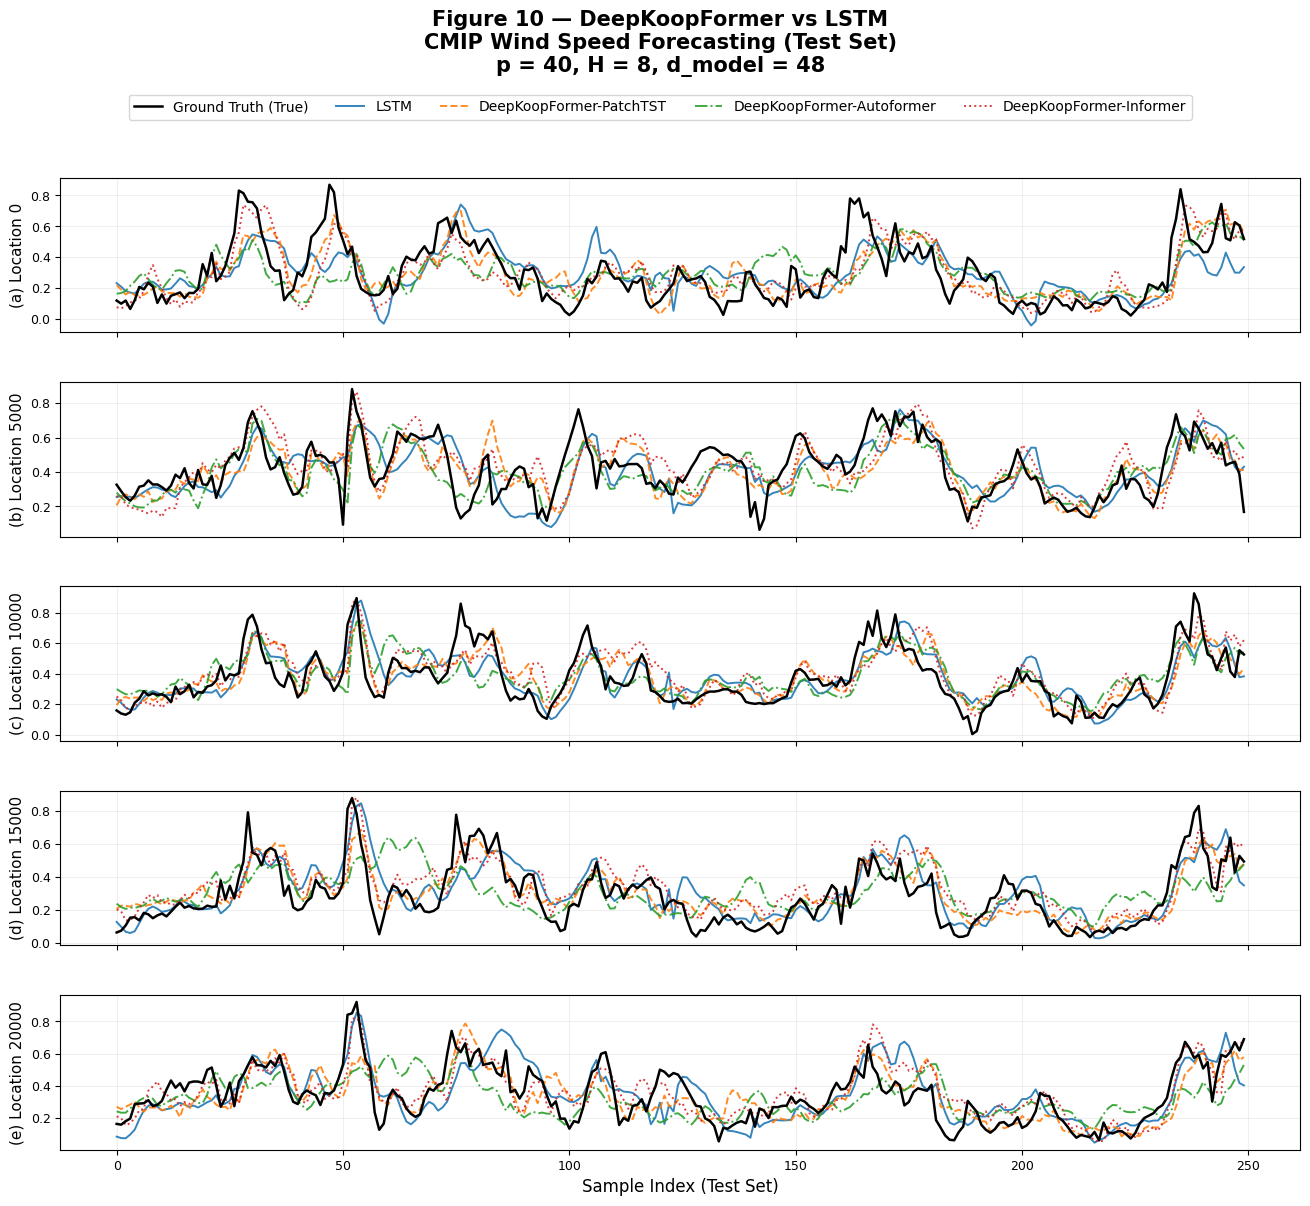

In [16]:
# Figure 10 — Test forecast, Scenario 4
p, h, d_model = 40, 8, 48
locations = [0, 5000, 10000, 15000, 20000]
models = ["LSTM", "PatchTST", "Autoformer", "Informer"]

styles = {
    "LSTM": {
        "label": "LSTM",
        "color": "tab:blue",
        "linestyle": "-",
    },
    "PatchTST": {
        "label": "DeepKoopFormer-PatchTST",
        "color": "tab:orange",
        "linestyle": "--",
    },
    "Autoformer": {
        "label": "DeepKoopFormer-Autoformer",
        "color": "tab:green",
        "linestyle": "-.",
    },
    "Informer": {
        "label": "DeepKoopFormer-Informer",
        "color": "tab:red",
        "linestyle": ":",
    },
}

predictions = {}
ground_truth = None
reference_data_hash = None
for model in models:
    path = RESULTS_DIR / f"{model.lower()}_p{p}_h{h}_d{d_model}.pt"

    ckpt = load_checkpoint(path)

    assert ckpt["model"] == model
    assert ckpt["patch_len"] == p
    assert ckpt["horizon"] == h
    assert ckpt["d_model"] == d_model
    assert ckpt["input_dim"] == 5
    assert ckpt["epochs"] == 4000
    # Bốn checkpoint phải thuộc cùng bộ dữ liệu
    if reference_data_hash is None:
        reference_data_hash = ckpt["data_hash"]
    else:
        assert ckpt["data_hash"] == reference_data_hash

    # (n_windows, 5 locations, 8 forecast steps)
    pred = ckpt["pred_test"].detach().cpu().numpy().reshape(-1, 5, h)
    truth = ckpt["truth_test"].detach().cpu().numpy().reshape(-1, 5, h)

    predictions[model] = pred[:, :, 0]

    if ground_truth is None:
        ground_truth = truth[:, :, 0]
    else:
        np.testing.assert_allclose(ground_truth, truth[:, :, 0], atol=1e-6)

# 250 consecutive test forecast windows, as in earlier forecast figures
n_show = min(250, len(ground_truth))
x = np.arange(n_show)

fig, axes = plt.subplots(
    5, 1,
    figsize=(16, 12),
    sharex=True,
    gridspec_kw={"hspace": 0.32}
)

for i, (ax, location) in enumerate(zip(axes, locations)):
    ax.plot(
        x, ground_truth[:n_show, i],
        color="black",
        linestyle="-",
        linewidth=1.8,
        label="Ground Truth (True)",
        zorder=10
    )

    for model in models:
        style = styles[model]

        ax.plot(
            x,
            predictions[model][:n_show, i],
            color=style["color"],
            linestyle=style["linestyle"],
            linewidth=1.4,
            label=style["label"],
            alpha=0.9
        )

    ax.set_ylabel(
        f"({chr(97+i)}) Location {location}",
        fontsize=11
    )
    ax.grid(alpha=0.2)
    ax.tick_params(labelsize=9)

axes[-1].set_xlabel("Sample Index (Test Set)", fontsize=12)

# Shared legend using the styles of the original forecast figures
handles, labels = axes[0].get_legend_handles_labels()

fig.legend(
    handles, labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 0.955),
    ncol=5,
    fontsize=10,
    frameon=True
)

fig.suptitle(
    "Figure 10 — DeepKoopFormer vs LSTM\n"
    "CMIP Wind Speed Forecasting (Test Set)\n"
    "p = 40, H = 8, d_model = 48",
    fontsize=15,
    fontweight="bold",
    y=1.02
)

fig.subplots_adjust(top=0.88, bottom=0.07)

safe_save_figure(
    fig,
    "figure10_test_forecasts.png"
)

plt.show()